In [5]:
# 1A Organize converted tiff files into Co/Tri, magnification, and channel (cell type) 
## MAKE A GLOBAL VAR TO STORE THE PATH NAMES FOR THE CHANNELS AND DAPI

import os
import shutil

import czifile
from tifffile import imsave

def convert_czi_to_tiff(folder_path):
    print(f"Beginning czi to tiff conversion...")
    for filename in os.listdir(folder_path):
        if filename.endswith(".czi"):
            czi_path = os.path.join(folder_path, filename)
            with czifile.CziFile(czi_path) as czi:
                image_arrays = czi.asarray()
                for channel_idx, channel_image in enumerate(image_arrays):
                    tiff_path = os.path.splitext(czi_path)[0] + f"_C_{channel_idx}.tiff"
                    imsave(tiff_path, channel_image)
                   
    print(f"✓ Converted czi files to tiffs")

# Move the czi file to the "Original_CZI" folder
    print(f"Beginning file organization...")
    co_culture_folder = os.path.join(folder_path, 'Co-culture')
    tri_culture_folder = os.path.join(folder_path, 'Tri-culture')
    czi_folder = os.path.join(folder_path, '0riginal CZI')

    os.makedirs(co_culture_folder, exist_ok=True)
    os.makedirs(tri_culture_folder, exist_ok=True)
    os.makedirs(czi_folder, exist_ok=True)

    files = os.listdir(folder_path)
    for file in files:
        if file.endswith('.czi'):
                shutil.move(os.path.join(folder_path, file), czi_folder)
        elif file.startswith('Co'):
                shutil.move(os.path.join(folder_path, file), co_culture_folder)
        elif file.startswith('Tri'):
                shutil.move(os.path.join(folder_path, file), tri_culture_folder)

    #Organize tiffs into magnification & channels
    tiff_folder1 = folder_path +'/Co-culture'
    tiff_folder2 = folder_path +'/Tri-culture'

    for tiff_folder in [tiff_folder1, tiff_folder2]:
        for tiff_file in os.listdir(tiff_folder):
            if tiff_file.endswith('.tiff'):
                magnification = tiff_file.split('_')[4]
                mag = magnification + 'x'
                channel = tiff_file.split('_')[6].split('.')[0]
                if channel == '0':
                    chan = 'Microglia'
                elif channel == '1':
                    chan = 'Astrocytes'
                elif channel == '2':
                    chan = 'Neurons'        
                elif channel == '3':
                    chan = 'DAPI'
                new_folder = os.path.join(tiff_folder, mag, chan)
                if not os.path.exists(new_folder):
                    os.makedirs(new_folder)
                os.rename(os.path.join(tiff_folder, tiff_file), os.path.join(new_folder, tiff_file))

In [6]:
# 1B Specify path for czi files
folder_path = "/Users/allisonpickle/Desktop/czi processing test"
convert_czi_to_tiff(folder_path)

print(f"✓ Files organized")

Beginning czi to tiff conversion...
✓ Converted czi files to tiffs
Beginning file organization...
✓ Files organized


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_34987/3179480811.py:19: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave(tiff_path, channel_image)


/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_34987/1695643233.py:23: DeprecationWarning: `product` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `prod` instead.
  basic.fit(images)
/var/folders/6k/phyprczs04ggvq8pz_vg4hd00000gn/T/ipykernel_34987/1695643233.py:39: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave(tiff_path, images_transformed)


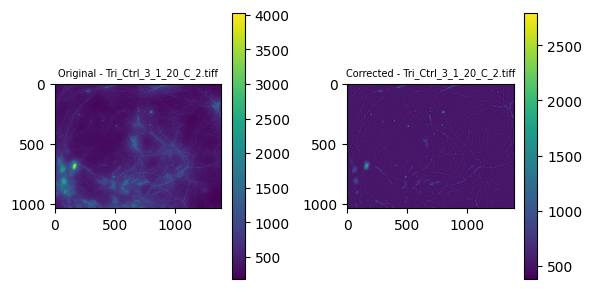

In [8]:
# 2A Illumination Correction
import numpy as np
from basicpy import BaSiC
from matplotlib import pyplot as plt
import os
from tifffile import imsave

def apply_correction(folder_path):
    
    # Iterate over each image file in the folder
    for filename in os.listdir(folder_path):
        if filename.endswith(".tiff"):
            # Specify the path to the TIFF file
            tiff_path = os.path.join(folder_path, filename)

            # Read the TIFF file
            images = plt.imread(tiff_path)

            # Change images to a 3D array with shape (1, height, width) from 2D
            images = np.expand_dims(images, axis=0)
            # basic = BaSiC(get_darkfield=True, smoothness_flatfield=1)
            basic = BaSiC(get_darkfield=True, smoothness_flatfield=0.5)
            basic.fit(images)

            # Apply the correction and plot them
            images_transformed = basic.transform(images)

            i = 0
            fig, axes = plt.subplots(1, 2, figsize=(6, 3))
            im = axes[0].imshow(images[i])
            fig.colorbar(im, ax=axes[0])
            axes[0].set_title(f"Original - {filename}", fontsize=7)  # Set the font size to 10
            im = axes[1].imshow(images_transformed[i])
            fig.colorbar(im, ax=axes[1])
            axes[1].set_title(f"Corrected - {filename}", fontsize=7)  # Set the font size to 10
            fig.tight_layout()

            # Save the images_transformed as a new TIFF file with the original file name
            # imsave(tiff_path, images_transformed)

In [9]:
#  2B Folder Specification for Illumination Correction

# Specify the list of folder paths
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    # #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",

    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

# Iterate over each folder path
for folder_path in folder_paths:
    # Call the function to apply the correction to all images in the folder
    apply_correction(folder_path)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia'

In [ ]:
# 2C Convert 3D tiff files to 2D after Illumination Correction
import os
import numpy as np
from tifffile import imread, imwrite
import matplotlib.pyplot as plt

def convert_3d_to_2d(folder_path):
    # Iterate over each TIFF file in the folder
    for filename in os.listdir(folder_path):
        if filename.endswith(".tiff"):
            # Construct the full path to the TIFF file
            tiff_path = os.path.join(folder_path, filename)

            # Load the 3D TIFF image
            image_3d = imread(tiff_path)

            # Convert the 3D image to a 2D image by taking the maximum intensity projection along the z-axis
            image_2d = np.max(image_3d, axis=0)

            # Save the 2D image as a TIFF file
            imwrite(tiff_path, image_2d)

            # # Display the 2D image
            # plt.imshow(image_2d, cmap='gray')
            # plt.axis('off')
            # plt.show()


In [ ]:
# 2D Folder Specification for 2D Conversion

# Specify the list of folder paths
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]
# Iterate over each folder path
for folder_path in folder_paths:
    # Call the function to apply the correction to all images in the folder
    convert_3d_to_2d(folder_path)

In [ ]:
# 3A Optimize Contrast mid tones
import os
import numpy as np
from skimage import io, exposure
import matplotlib.pyplot as plt

def optimize_contrast(folder_path):
    """Optimize the contrast of images in a folder and display the results

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images
    output_folder : str
        Path to the folder where the optimized images will be saved

    Returns
    -------
    None
    """
    # Create the output folder if it doesn't exist
    output_folder = folder_path
    os.makedirs(output_folder, exist_ok=True)

    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        img = io.imread(image_path)

        # Normalize the image to be between -1 and 1
        img = img / np.max(np.abs(img))

        # Optimize the contrast of the image
        img_optimized = exposure.equalize_adapthist(img)

        # Save the optimized image to the output folder
        output_path = os.path.join(output_folder, image_file)
        io.imsave(output_path, img_optimized)

        # Display the original image and the optimized image side by side
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img, cmap='gray')
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        axes[1].imshow(img_optimized, cmap='gray')
        axes[1].set_title('Optimized Image')
        axes[1].axis('off')
        plt.show()


In [ ]:
# 3B Specify the folders for optimize contrast
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

# Iterate over each folder path
for folder_path in folder_paths:
    # Call the function to apply the correction to all images in the folder
    optimize_contrast(folder_path)

In [ ]:
# 4A Test Threshold Options

import os
from skimage import io
from skimage.filters import try_all_threshold
import matplotlib.pyplot as plt

def test_threshold_options(folder_path):
    """Test threshold options for images in a folder

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images

    Returns
    -------
    None
    """
    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image
        img = io.imread(image_path)
        fig, ax = try_all_threshold(img, figsize=(20, 18), verbose=False)
        
        plt.show()

In [ ]:
# 4B Preview Threshold Before Applying

# Specify the list of folder paths
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

# Iterate over each folder path
for folder_path in folder_paths:
    # Call the function to apply the correction to all images in the folder
    test_threshold_options(folder_path + "Optimized Contrast")


In [ ]:
# 4C Apply Otsu Threshold
import os
from skimage import io, filters

def apply_otsu_threshold(folder_path):
    """Apply Otsu threshold filter to images in a folder

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the images

    Returns
    -------
    None
    """
    # Create a subfolder for the thresholded images
    result_folder = os.path.join(folder_path, "Thresholded")
    os.makedirs(result_folder, exist_ok=True)

    # Get a list of all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image
        img = io.imread(image_path)

        # Apply Otsu threshold filter
        threshold_value = filters.threshold_otsu(img)
        binary_image = img > threshold_value

        # Save the thresholded image to the result folder
        result_image_path = os.path.join(result_folder, image_file)
        io.imsave(result_image_path, binary_image.astype('uint8') * 255)

        # Display the original image and the resulting binary image side by side
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img, cmap='gray')
        axes[0].set_title('Original Image')
        axes[0].axis('off')
        axes[1].imshow(binary_image, cmap='gray')
        axes[1].set_title('Binary Image (Otsu Threshold)')
        axes[1].axis('off')
        plt.show()


In [ ]:
# 4D Specify the folders for otsu threshold
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

# Iterate over each folder path
for folder_path in folder_paths:
    # Call the function to apply the correction to all images in the folder
    apply_otsu_threshold(folder_path)


In [ ]:
# 5A Remove Islands in non-DAPI Channels
from skimage.morphology import disk
from skimage import morphology

def Remove_Islands(folder_path, output_folder, magnification):
    """Process all TIFF images in a folder by applying white tophat transformation and saving the final images.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the TIFF images
    output_folder : str
        Path to the folder to save the final images
    magnification : str
        Magnification level of the images

    Returns
    -------
    None
    """
    # Get a list of all TIFF image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Define the disk radius for different magnifications
    disk_radius = {
        '5x': 2,
        '10x': 1.7,
        '20x': 1.7
    }

    # Get the disk radius based on the magnification
    radius = disk_radius.get(magnification)

    if radius is None:
        raise ValueError(f"Invalid magnification: {magnification}")

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image file into a NumPy array
        image = io.imread(image_path)

        footprint = disk(radius)
        res = morphology.white_tophat(image, footprint)

        fig, ax = plt.subplots(ncols=3, figsize=(20, 8))
        ax[0].set_title(f'Original - {image_file}')
        ax[0].imshow(image, cmap='gray')
        ax[1].set_title(f'White Tophat')
        ax[1].imshow(res, cmap='gray')
        ax[2].set_title(f'Complementary')
        ax[2].imshow(image - res, cmap='gray')

        final_image_path = os.path.join(output_folder, image_file)
        io.imsave(final_image_path, image - res)
        plt.show()

# 4D Specify the folders for otsu threshold
folder_paths = [
   #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
]

for folder_path in folder_paths:
    # Extract the magnification from the folder path
    magnification = folder_path.split('/')[-2]

    # Call the function to apply the correction to all images in the folder
    output_folder = folder_path + "/Thresholded"
    Remove_Islands(folder_path + "/Thresholded", output_folder, magnification)

In [ ]:
# 5B Remove Islands in DAPI Channels
from skimage.morphology import disk
from skimage import morphology

def Remove_DAPI_Islands(folder_path, output_folder, magnification):
    """Process all TIFF images in a folder by applying white tophat transformation and saving the final images.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the TIFF images
    output_folder : str
        Path to the folder to save the final images
    magnification : str
        Magnification level of the images

    Returns
    -------
    None
    """
    # Get a list of all TIFF image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Define the disk radius for different magnifications
    disk_radius = {
        '5x': 2.5,
        '10x': 5,
        '20x': 5
    }

    # Get the disk radius based on the magnification
    radius = disk_radius.get(magnification)

    if radius is None:
        raise ValueError(f"Invalid magnification: {magnification}")

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the image file into a NumPy array
        image = io.imread(image_path)

        footprint = disk(radius)
        res = morphology.white_tophat(image, footprint)

        fig, ax = plt.subplots(ncols=3, figsize=(20, 8))
        ax[0].set_title(f'Original - {image_file}')
        ax[0].imshow(image, cmap='gray')
        ax[1].set_title(f'White Tophat')
        ax[1].imshow(res, cmap='gray')
        ax[2].set_title(f'Complementary')
        ax[2].imshow(image - res, cmap='gray')

        final_image_path = os.path.join(output_folder, image_file)
        io.imsave(final_image_path, image - res)
        plt.show()

# 4D Specify the folders for otsu threshold
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

for folder_path in folder_paths:
    # Extract the magnification from the folder path
    magnification = folder_path.split('/')[-2]

    # Call the function to apply the correction to all images in the folder
    output_folder = folder_path + "/Thresholded"
    Remove_DAPI_Islands(folder_path + "/Thresholded", output_folder, magnification)


In [ ]:
# 6A Apply Watershed Segmentation to DAPI

from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from scipy import ndimage as ndi
import numpy as np
import matplotlib.pyplot as plt
import skimage.io as io
import os

def Watershed_Segmentation(folder_path):
    """Perform watershed segmentation on all images in the input folder.

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the thresholded images.

    Returns
    -------
    None
    """
    # Get a list of all TIFF image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]

    # Iterate over each image file
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)

        # Read the input image
        image = io.imread(image_path)

        # Compute the Euclidean distance from the background
        distance = ndi.distance_transform_edt(image)

        # Find the local maxima in the distance map
        coordinates = peak_local_max(distance, labels=image, min_distance=3) #Adjust this value

        # Create an empty array of zeros with the same shape as the image
        markers = np.zeros_like(image, dtype=int)

        # Label the local maxima coordinates
        markers[coordinates[:, 0], coordinates[:, 1]] = np.arange(len(coordinates)) + 1

        # Perform watershed segmentation
        labels = watershed(-distance, markers, mask=image)

        # Save the segmented image with the original file name
        output_path = os.path.splitext(image_path)[0] + '_watershed.tiff'
        io.imsave(output_path, labels.astype(np.uint8))

        # Display the results
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(image, cmap='gray')
        axes[0].set_title('Input Image')
        axes[0].axis('off')
        axes[1].imshow(distance, cmap='gray')
        axes[1].set_title('Distance Map')
        axes[1].axis('off')
        axes[2].imshow(labels, cmap='nipy_spectral')
        axes[2].set_title('Segmented Image')
        axes[2].axis('off')
        plt.tight_layout()
        plt.show()


In [ ]:
# 6B Call DAPI Watershed

folder_paths = [
    #5x Co

    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    #5x Tri

    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    #10x Co

    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
    #10x Tri

    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
    #20x Co

    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
    #20x Tri

    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

# Iterate over each folder path
for folder_path in folder_paths:
    # Call the function to perform watershed segmentation on all images in the folder
    Watershed_Segmentation(folder_path + "/Thresholded")


In [ ]:
# 7A DAPI Count
import cv2
import os
import pandas as pd
import matplotlib.pyplot as plt
from openpyxl import load_workbook
from openpyxl.utils.dataframe import dataframe_to_rows

def DAPI_Count(folder_path, min_area, max_area):
    """Count the number of contours in each image file in the specified folder that meet the contour area specification.
    
    Parameters
    ----------
    folder_path : str
        Path to the folder containing the image files.
    min_area : int
        Minimum contour area.
    max_area : int
        Maximum contour area.
    
    Returns
    -------
    None
    """
    output_file = "/Users/allisonpickle/Desktop/Test/DAPI_Count.xlsx"

    # Read all image files in the folder
    image_files = [file for file in os.listdir(folder_path) if file.endswith('.tiff')]
        
    # Create an empty DataFrame to store the counts
    counts_df = pd.DataFrame(columns=['Image Name', 'Count'])
        
    # Check if the Excel file already exists
    excel_file_path = '/Users/allisonpickle/Desktop/Test/DAPI_Count.xlsx'
            
    if os.path.exists(excel_file_path):
        # Load the existing workbook
        workbook = load_workbook(excel_file_path)
        # Select the active sheet
        sheet = workbook.active
    else:
        # Create a new workbook and select the active sheet
        workbook = Workbook()
        sheet = workbook.active
        # Write the header row
        header_row = ["Culture", "Group", "Well Number", "Image Number", "DAPI Count"]
        sheet.append(header_row)
        
    for image_file in image_files:
        # Construct the full path to the image file
        image_path = os.path.join(folder_path, image_file)
            
        image = cv2.imread(image_path)

        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)   
        contours, _ = cv2.findContours(gray_image, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE) # Find contours in the grayscale image
            
        # Initialize a counter for the areas that meet the contour area specification
        count = 0
            
        # Iterate over the contours
        for contour in contours:
            # Calculate the area of the contour
            area = cv2.contourArea(contour)
                
            # Check if the area meets the contour area specification
            if min_area <= area <= max_area:
                count += 1
                # Draw the contour on the original image
                cv2.drawContours(image, [contour], -1, (0, 255, 0), 2)
            
        # Display the original image with the counted areas outlined
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(f'Counted Areas in {image_file}')
        plt.axis('off')
        plt.show()
        
        # Extract the culture_type, group_type, well_number, and image_number from the filename
        filename_parts = image_file.split("_") # First element of the filename
        culture_type = filename_parts[0]
        group_type = filename_parts[1]
        well_number = filename_parts[2]
        image_number = filename_parts[3]
        
        # Write the DataFrame to the sheet
        data = [[culture_type, group_type, well_number, image_number, count]]
        df = pd.DataFrame(data, columns=["Culture", "Group", "Well Number", "Image Number", "DAPI Count"])
        for row in dataframe_to_rows(df, index=False, header=False):
            sheet.append(row)

    # Save the workbook to the specified output file
    workbook.save(output_file)

folder_paths = [
    # #5x Co

    # "/Users/allisonpickle/Desktop/Test/Co-culture/5x/DAPI",
    # #5x Tri

    # "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/DAPI",
    # #10x Co


        "/Users/allisonpickle/Desktop/Test/Co-culture/10x/DAPI",
        #10x Tri

        "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/DAPI",
        # #20x Co

        # "/Users/allisonpickle/Desktop/Test/Co-culture/20x/DAPI",
        # #20x Tri

        # "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/DAPI"
]

min_area = 50  
max_area = 1000
for folder_path in folder_paths:
    folder_paths_thresholded = folder_path + "/Thresholded"
    DAPI_Count(folder_paths_thresholded, min_area, max_area)


In [ ]:
# 7A Measure Surface Area Coverage
import os
import cv2
import pandas as pd
from openpyxl import Workbook
from openpyxl.utils.dataframe import dataframe_to_rows

def measure_and_save_white_area_percentage(folder_paths, output_file):
    if not os.path.exists(output_file):
        workbook = Workbook()
        workbook.save(output_file)

    data = []
    for folder_path in folder_paths:

        head, tail = os.path.split(folder_path) #Pull out cell type
        folder_name = os.path.split(head)[1]

        for filename in os.listdir(folder_path):
            
            if filename.endswith(".jpg") or filename.endswith(".tiff"):
                image_path = os.path.join(folder_path, filename)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
                total_pixels = image.size
                white_pixels = cv2.countNonZero(image)
                white_area_percentage = (white_pixels / total_pixels) * 100

                culture_type = filename.split("_")[0]  # First element of the filename
                group_type = filename.split("_")[1]  # Second element of the filename
                well_number = filename.split("_")[2]  # Third element of the filename
                image_number = filename.split("_")[3]  # Fourth element of the filename
                data.append([culture_type, group_type, well_number, image_number, folder_name, white_area_percentage])

    df = pd.DataFrame(data, columns=["Culture", "Group", "Well Number", "Image Number", "Channel", "Surface Area Coverage %"])

    # Create a new workbook and select the active sheet
    workbook = Workbook()
    sheet = workbook.active

    # Write the DataFrame to the sheet
    for row in dataframe_to_rows(df, index=False, header=True):
        sheet.append(row)

    # Save the workbook to the specified output file
    workbook.save(output_file)

folder_paths = [
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons/Thresholded", 
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes/Thresholded", 
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia/Thresholded"
]

output_file = "/Users/allisonpickle/Desktop/Test/Surface_Area_Percentage.xlsx"
measure_and_save_white_area_percentage(folder_paths, output_file)

In [ ]:
# 7B Call Measure Surface Area Coverage

# Specify the folder path
folder_paths = [
    #5x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/5x/Neurons",
    #5x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/5x/Neurons",
    #10x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/10x/Neurons",
    #10x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/10x/Neurons",
    #20x Co
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Co-culture/20x/Neurons",
    #20x Tri
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Microglia",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Astrocytes",
    "/Users/allisonpickle/Desktop/Test/Tri-culture/20x/Neurons",
]

for folder_path in folder_paths: 
    output_path = "/Users/allisonpickle/Desktop/Test"
    # Call the function to populate the dataframe with white area percentage
    measure_white_area_percentage(folder_path + "/Thresholded", output_path)
